# Proyecto Estadísticas de YouTube - Avances II
**Procesamiento de Lenguaje Natural - Especialización en Inteligencia Artificial**
** Jenifer Cardenas Aguilera**

Este notebook responde las preguntas de Avances II: qué análisis estadísticos se pueden hacer, qué
variables se eligen para predecir, cuántos modelos se probaron, con qué herramientas, cuál se
seleccionó, con qué desempeño y bajo qué métricas, y si un solo modelo es suficiente.

Se trabajan **dos problemas** con el mismo dataset:

- **Modelo A - Sentimiento de comentarios** (clasificación de texto): dado el texto de un comentario, predecir si es negativo, neutro o positivo.
- **Modelo B - Desempeño del video** (regresión): predecir los likes de un video a partir de sus comentarios (y, como comparación, de sus vistas).

> Antes de ejecutar: deja los archivos CSV del dataset en la misma carpeta del notebook
> (o cambia `DATA_DIR` en la primera celda de código).

In [3]:
import re, unicodedata, warnings, glob, os
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from scipy import stats

from sklearn.model_selection import train_test_split, cross_val_score, StratifiedKFold, KFold
from sklearn.feature_extraction.text import TfidfVectorizer
from sklearn.pipeline import make_pipeline
from sklearn.dummy import DummyClassifier, DummyRegressor
from sklearn.naive_bayes import MultinomialNB
from sklearn.linear_model import LogisticRegression, LinearRegression
from sklearn.svm import LinearSVC
from sklearn.ensemble import RandomForestRegressor, GradientBoostingRegressor
from sklearn.metrics import (accuracy_score, f1_score, classification_report,
                             mean_absolute_error, mean_squared_error, r2_score)

warnings.filterwarnings("ignore")
RANDOM_STATE = 42
DATA_DIR = r"C:\Users\fefy3\Documents\Universidad\Procesamiento de lenguaje natural\Tareas\youtube\subir"          # carpeta donde estan los CSV
print("Librerias cargadas")

Librerias cargadas


## 1. Carga de los datos
El notebook busca solo los dos archivos: el que tiene la columna de **vistas** (estadísticas de los videos)
y el que tiene la columna de **comentarios** (texto de los comentarios).

In [4]:
def buscar_columna(df, opciones):
    mapa = {c.lower().strip(): c for c in df.columns}
    for o in opciones:
        if o in mapa:
            return mapa[o]
    return None

videos, comentarios = None, None
for ruta in glob.glob(os.path.join(DATA_DIR, "*.csv")):
    try:
        tmp = pd.read_csv(ruta)
    except Exception:
        tmp = pd.read_csv(ruta, encoding="latin-1")
    if buscar_columna(tmp, ["views", "view count"]) is not None and videos is None:
        videos, ruta_videos = tmp, ruta
    elif buscar_columna(tmp, ["comment", "comment text", "text"]) is not None and comentarios is None:
        comentarios, ruta_comentarios = tmp, ruta

assert videos is not None, "No encontre el CSV de videos (con columna Views). Revisa DATA_DIR."
assert comentarios is not None, "No encontre el CSV de comentarios (con columna Comment). Revisa DATA_DIR."
print("Videos:     ", ruta_videos, videos.shape)
print("Comentarios:", ruta_comentarios, comentarios.shape)

# Nombres de columnas (el dataset original usa Video ID, Views, Likes, Comments, Comment, Sentiment)
C_VID_V = buscar_columna(videos, ["video id", "video_id", "videoid"])
C_VIEWS = buscar_columna(videos, ["views", "view count"])
C_LIKES = buscar_columna(videos, ["likes", "like count"])
C_NCOM  = buscar_columna(videos, ["comments", "comment count"])
C_KW    = buscar_columna(videos, ["keyword", "category"])
C_VID_C = buscar_columna(comentarios, ["video id", "video_id", "videoid"])
C_TEXT  = buscar_columna(comentarios, ["comment", "comment text", "text"])
C_SENT  = buscar_columna(comentarios, ["sentiment", "label"])
C_COMLIKES = buscar_columna(comentarios, ["likes", "like count"])
print("Columnas detectadas:", dict(vid_v=C_VID_V, views=C_VIEWS, likes=C_LIKES, ncom=C_NCOM,
                                   kw=C_KW, vid_c=C_VID_C, text=C_TEXT, sent=C_SENT))

Videos:      C:\Users\fefy3\Documents\Universidad\Procesamiento de lenguaje natural\Tareas\youtube\subir\videos-stats.csv (1881, 8)
Comentarios: C:\Users\fefy3\Documents\Universidad\Procesamiento de lenguaje natural\Tareas\youtube\subir\comments.csv (18409, 5)
Columnas detectadas: {'vid_v': 'Video ID', 'views': 'Views', 'likes': 'Likes', 'ncom': 'Comments', 'kw': 'Keyword', 'vid_c': 'Video ID', 'text': 'Comment', 'sent': 'Sentiment'}


In [5]:
print("=== VIDEOS ===")
display(videos.head(3))
print(videos.dtypes)
print("\n=== COMENTARIOS ===")
display(comentarios.head(5))
print(comentarios.dtypes)

=== VIDEOS ===


,Unnamed: 0,Title,Video ID,Published At,Keyword,Likes,Comments,Views
0,0,Apple Pay Is Killing the Physical Wallet After...,wAZZ-UWGVHI,2022-08-23,tech,3407.0,672.0,135612.0
1,1,The most EXPENSIVE thing I own.,b3x28s61q3c,2022-08-24,tech,76779.0,4306.0,1758063.0
2,2,My New House Gaming Setup is SICK!,4mgePWWCAmA,2022-08-23,tech,63825.0,3338.0,1564007.0


Unnamed: 0        int64
Title               str
Video ID            str
Published At        str
Keyword             str
Likes           float64
Comments        float64
Views           float64
dtype: object

=== COMENTARIOS ===


,Unnamed: 0,Video ID,Comment,Likes,Sentiment
0,0,wAZZ-UWGVHI,Let's not forget that Apple Pay in 2014 requir...,95.0,1.0
1,1,wAZZ-UWGVHI,Here in NZ 50% of retailers don’t even have co...,19.0,0.0
2,2,wAZZ-UWGVHI,I will forever acknowledge this channel with t...,161.0,2.0
3,3,wAZZ-UWGVHI,Whenever I go to a place that doesn’t take App...,8.0,0.0
4,4,wAZZ-UWGVHI,"Apple Pay is so convenient, secure, and easy t...",34.0,2.0


Unnamed: 0      int64
Video ID          str
Comment           str
Likes         float64
Sentiment     float64
dtype: object


## 2. Calidad de los datos
Se revisan nulos, duplicados, comentarios vacíos, el balance de las clases de sentimiento
y si los comentarios se pueden unir con su video.

In [6]:
print("Nulos en videos:\n", videos.isna().sum(), "\n")
print("Nulos en comentarios:\n", comentarios.isna().sum(), "\n")
print("Videos duplicados:", videos.duplicated().sum())
print("Comentarios duplicados (fila completa):", comentarios.duplicated().sum())
print("Comentarios con texto repetido:", comentarios[C_TEXT].duplicated().sum())

print("\nComentarios por video (segun la ficha deben ser 10 por video, los mas relevantes):")
print(comentarios.groupby(C_VID_C).size().describe().round(1))

huerfanos = ~comentarios[C_VID_C].isin(videos[C_VID_V])
print("\nComentarios cuyo video no esta en el archivo de videos:", int(huerfanos.sum()))

if C_SENT:
    print("\nDistribucion del sentimiento:")
    print(comentarios[C_SENT].value_counts(dropna=False))
    print((comentarios[C_SENT].value_counts(normalize=True)*100).round(1).astype(str) + " %")

Nulos en videos:
 Unnamed: 0      0
Title           0
Video ID        0
Published At    0
Keyword         0
Likes           2
Comments        2
Views           2
dtype: int64 

Nulos en comentarios:
 Unnamed: 0    0
Video ID      0
Comment       1
Likes         0
Sentiment     0
dtype: int64 

Videos duplicados: 0
Comentarios duplicados (fila completa): 0
Comentarios con texto repetido: 414

Comentarios por video (segun la ficha deben ser 10 por video, los mas relevantes):
count    1869.0
mean        9.8
std         1.4
min         1.0
25%        10.0
50%        10.0
75%        10.0
max        20.0
dtype: float64

Comentarios cuyo video no esta en el archivo de videos: 0

Distribucion del sentimiento:
Sentiment
2.0    11432
1.0     4639
0.0     2338
Name: count, dtype: int64
Sentiment
2.0    62.1 %
1.0    25.2 %
0.0    12.7 %
Name: proportion, dtype: str


In [7]:
# Limpieza aplicada
com = comentarios.dropna(subset=[C_TEXT]).copy()
com[C_TEXT] = com[C_TEXT].astype(str)
com = com[com[C_TEXT].str.strip().str.len() > 0]
com = com.drop_duplicates()
if C_SENT:
    com = com.dropna(subset=[C_SENT])

# Segun la ficha del dataset, -1 significa "dato no visible" (likes ocultos, comentarios desactivados, etc.)
vid = videos.copy()
for c in [C_VIEWS, C_LIKES, C_NCOM]:
    if c:
        print(f"Videos con {c} = -1 (no visible):", int((vid[c] == -1).sum()))
        vid[c] = vid[c].replace(-1, np.nan)
vid = vid.dropna(subset=[C_VIEWS, C_LIKES]).drop_duplicates(subset=[C_VID_V]).copy()
vid = vid[vid[C_VIEWS] > 0]
print("Comentarios antes/despues de limpiar:", len(comentarios), "->", len(com))
print("Videos antes/despues de limpiar:     ", len(videos), "->", len(vid))

Videos con Views = -1 (no visible): 0
Videos con Likes = -1 (no visible): 7
Videos con Comments = -1 (no visible): 2
Comentarios antes/despues de limpiar: 18409 -> 18408
Videos antes/despues de limpiar:      1881 -> 1861


## 3. Análisis estadístico
Además del `describe()`, se hacen análisis menos obvios: asimetría de las variables, correlación de
Spearman (apropiada porque vistas y likes no son normales), y una prueba de Kruskal-Wallis para ver si
el engagement cambia entre categorías.

In [8]:
num = vid[[C_VIEWS, C_LIKES] + ([C_NCOM] if C_NCOM else [])]
display(num.describe().round(1))
print("Asimetria (skew):")
print(num.skew().round(2))
print("\nUna asimetria muy por encima de 1 indica cola larga: pocos videos concentran casi todas las vistas.")

,Views,Likes,Comments
count,1.861000e+03,1861.0,1859.0
mean,1.168600e+07,169674.2,7848.5
std,1.089629e+08,797227.0,37997.4
min,2.500000e+01,0.0,0.0
25%,8.519100e+04,2707.0,202.0
50%,5.899070e+05,14899.0,820.0
75%,2.812807e+06,60991.0,3395.0
max,4.034122e+09,16445558.0,732818.0


Asimetria (skew):
Views       29.44
Likes       11.61
Comments    12.48
dtype: float64

Una asimetria muy por encima de 1 indica cola larga: pocos videos concentran casi todas las vistas.


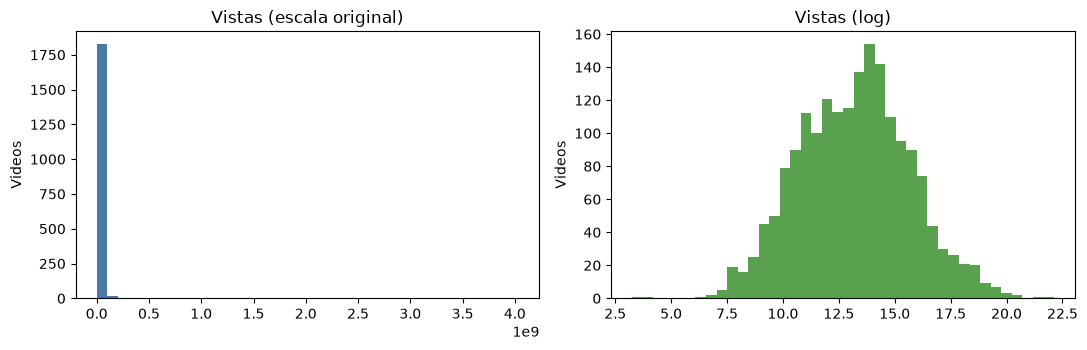

In [9]:
fig, axes = plt.subplots(1, 2, figsize=(11, 3.6))
axes[0].hist(vid[C_VIEWS], bins=40, color="#4c78a8"); axes[0].set_title("Vistas (escala original)")
axes[1].hist(np.log1p(vid[C_VIEWS]), bins=40, color="#59a14f"); axes[1].set_title("Vistas (log)")
for a in axes: a.set_ylabel("Videos")
plt.tight_layout(); plt.savefig("fig_vistas.png", dpi=150); plt.show()

In [10]:
cols = [C_VIEWS, C_LIKES] + ([C_NCOM] if C_NCOM else [])
corr = vid[cols].corr(method="spearman").round(3)
display(corr)

vid["tasa_likes"] = vid[C_LIKES] / vid[C_VIEWS].replace(0, np.nan)
print("Tasa de likes por video (likes / vistas): mediana =", round(vid["tasa_likes"].median(), 4))

if C_KW:
    grupos = [g["tasa_likes"].dropna().values for _, g in vid.groupby(C_KW) if g["tasa_likes"].notna().sum() > 2]
    if len(grupos) > 1:
        h, p = stats.kruskal(*grupos)
        print(f"Kruskal-Wallis de la tasa de likes entre categorias ({C_KW}): H = {h:.2f}, p = {p:.4f}")
        print("p < 0.05 sugiere que el engagement si cambia segun la categoria.")

,Views,Likes,Comments
Views,1.000,0.949,0.839
Likes,0.949,1.000,0.872
Comments,0.839,0.872,1.000


Tasa de likes por video (likes / vistas): mediana = 0.0275
Kruskal-Wallis de la tasa de likes entre categorias (Keyword): H = 716.01, p = 0.0000
p < 0.05 sugiere que el engagement si cambia segun la categoria.


### Sentimiento de los comentarios por video
Se calcula, para cada video, qué proporción de sus comentarios son positivos, neutros y negativos.
Luego se revisa si esa proporción se relaciona con el engagement del video.

In [11]:
# Convertir el sentimiento a un nombre legible
if C_SENT:
    s = com[C_SENT]
    if pd.api.types.is_numeric_dtype(s):
        # En el dataset de Kaggle: 0 = negativo, 1 = neutro, 2 = positivo (verificar en la ficha del dataset)
        mapa = {0: "negativo", 1: "neutro", 2: "positivo"}
        com["sent_txt"] = s.map(mapa)
    else:
        com["sent_txt"] = s.astype(str).str.lower().str.strip()
    print(com["sent_txt"].value_counts())

sent_txt
positivo    11432
neutro       4638
negativo     2338
Name: count, dtype: int64


Videos con comentarios y estadisticas: 1861
Spearman entre sentimiento medio de los comentarios y la tasa de likes: rho = 0.065, p = 0.0051
Spearman entre sentimiento medio y log(likes):                          rho = 0.154, p = 0.0000


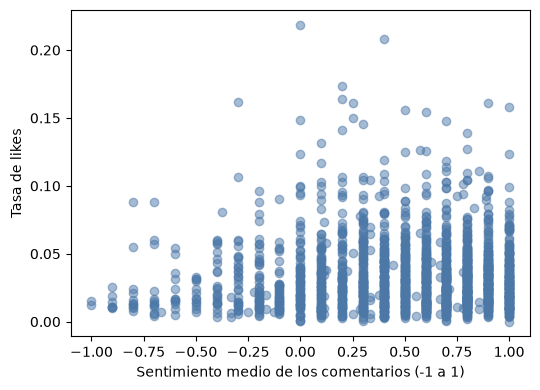

In [12]:
if C_SENT:
    tabla = pd.crosstab(com[C_VID_C], com["sent_txt"], normalize="index")
    for c in ["positivo", "neutro", "negativo"]:
        if c not in tabla: tabla[c] = 0.0
    tabla.columns = ["prop_" + c for c in tabla.columns]
    tabla["n_comentarios_muestra"] = com.groupby(C_VID_C).size()
    tabla["sent_medio"] = tabla["prop_positivo"] - tabla["prop_negativo"]   # entre -1 y 1

    dv = vid.merge(tabla, left_on=C_VID_V, right_index=True, how="inner")
    print("Videos con comentarios y estadisticas:", len(dv))

    r, p = stats.spearmanr(dv["sent_medio"], dv["tasa_likes"], nan_policy="omit")
    print(f"Spearman entre sentimiento medio de los comentarios y la tasa de likes: rho = {r:.3f}, p = {p:.4f}")
    r2, p2 = stats.spearmanr(dv["sent_medio"], np.log1p(dv[C_LIKES]), nan_policy="omit")
    print(f"Spearman entre sentimiento medio y log(likes):                          rho = {r2:.3f}, p = {p2:.4f}")

    plt.figure(figsize=(5.5, 4))
    plt.scatter(dv["sent_medio"], dv["tasa_likes"], alpha=0.5, color="#4c78a8")
    plt.xlabel("Sentimiento medio de los comentarios (-1 a 1)"); plt.ylabel("Tasa de likes")
    plt.tight_layout(); plt.savefig("fig_sentimiento_vs_likes.png", dpi=150); plt.show()

## 4. Modelo A - Clasificación del sentimiento de los comentarios
**Variable a predecir:** `Sentiment` (negativo / neutro / positivo).
**Variable de entrada:** el texto del comentario, convertido en números con **TF-IDF**.
**Evaluación:** 75 % entrenamiento / 25 % prueba (estratificado) y validación cruzada de 5 particiones.
**Métricas:** accuracy y F1 macro (promedia el F1 de cada clase; es más justa si las clases están desbalanceadas).

Se compara contra un **modelo base** (`DummyClassifier`, que siempre responde la clase más frecuente).

In [13]:
def normalizar(texto):
    texto = str(texto).lower()
    texto = unicodedata.normalize("NFKD", texto).encode("ascii", "ignore").decode("utf-8")
    texto = re.sub(r"[^a-z0-9\s]", " ", texto)
    return re.sub(r"\s+", " ", texto).strip()

if C_SENT:
    com["texto_limpio"] = com[C_TEXT].map(normalizar)
    datos_a = com[com["texto_limpio"].str.len() > 0]
    X_tr, X_te, y_tr, y_te = train_test_split(
        datos_a["texto_limpio"], datos_a["sent_txt"], test_size=0.25,
        random_state=RANDOM_STATE, stratify=datos_a["sent_txt"])
    print("Entrenamiento:", len(X_tr), "| Prueba:", len(X_te))

Entrenamiento: 13629 | Prueba: 4544


In [14]:
if C_SENT:
    modelos_a = {
        "Base (clase mayoritaria)": DummyClassifier(strategy="most_frequent"),
        "Naive Bayes":              MultinomialNB(),
        "Regresion logistica":      LogisticRegression(max_iter=1000, class_weight="balanced"),
        "SVM lineal":               LinearSVC(class_weight="balanced"),
    }
    filas = []
    skf = StratifiedKFold(n_splits=5, shuffle=True, random_state=RANDOM_STATE)
    for nombre, clf in modelos_a.items():
        pipe = make_pipeline(TfidfVectorizer(ngram_range=(1, 2), min_df=2), clf)
        pipe.fit(X_tr, y_tr)
        pred = pipe.predict(X_te)
        cv = cross_val_score(pipe, X_tr, y_tr, cv=skf, scoring="f1_macro")
        filas.append({"Modelo": nombre,
                      "Accuracy": accuracy_score(y_te, pred),
                      "F1 macro": f1_score(y_te, pred, average="macro"),
                      "F1 macro (CV 5 part.)": cv.mean()})
    res_a = pd.DataFrame(filas).sort_values("F1 macro", ascending=False).round(3).reset_index(drop=True)
    display(res_a)

,Modelo,Accuracy,F1 macro,F1 macro (CV 5 part.)
0,SVM lineal,0.770,0.686,0.663
1,Regresion logistica,0.747,0.679,0.666
2,Naive Bayes,0.663,0.378,0.376
3,Base (clase mayoritaria),0.627,0.257,0.257


In [15]:
if C_SENT:
    mejor_a = res_a.iloc[0]["Modelo"]
    print("Modelo A seleccionado:", mejor_a)
    pipe_mejor = make_pipeline(TfidfVectorizer(ngram_range=(1, 2), min_df=2), modelos_a[mejor_a])
    pipe_mejor.fit(X_tr, y_tr)
    print(classification_report(y_te, pipe_mejor.predict(X_te), zero_division=0))

Modelo A seleccionado: SVM lineal
              precision    recall  f1-score   support

    negativo       0.59      0.54      0.56       584
      neutro       0.63      0.63      0.63      1113
    positivo       0.86      0.87      0.87      2847

    accuracy                           0.77      4544
   macro avg       0.69      0.68      0.69      4544
weighted avg       0.77      0.77      0.77      4544



## 5. Modelo B - Predicción del desempeño del video (likes)
**Variable a predecir:** `log(1 + likes)`. Se usa logaritmo porque los likes tienen una cola muy larga (ver sección 3).
**Variables de entrada, en dos configuraciones:**

- **Solo comentarios:** proporción de comentarios positivos / neutros / negativos, sentimiento medio, likes promedio de los comentarios y largo promedio del texto. (No se usa la *cantidad* de comentarios de la muestra porque el dataset trae siempre 10 por video.)
- **Comentarios + estadísticas del video:** lo anterior más `log(1 + vistas)` y `log(1 + total de comentarios del video)`.

La segunda configuración sirve de referencia: las vistas son un predictor muy fuerte de los likes,
así que comparar ambas muestra cuánto aportan realmente los comentarios.
**Métricas:** MAE, RMSE y R² (sobre la escala logarítmica), con validación cruzada de 5 particiones.

In [16]:
if C_SENT:
    dv = dv.copy()
    dv["y"] = np.log1p(dv[C_LIKES])
    dv["log_views"] = np.log1p(dv[C_VIEWS])
    # Cada video trae solo 10 comentarios, asi que su cantidad no sirve como variable.
    # En su lugar: likes promedio de esos comentarios y su longitud promedio.
    com["largo"] = com[C_TEXT].str.len()
    agg = {"largo_medio": ("largo", "mean")}
    if C_COMLIKES:
        agg["likes_com_medio"] = (C_COMLIKES, "mean")
    extra = com.groupby(C_VID_C).agg(**agg)
    if C_COMLIKES:
        extra["log_likes_com_medio"] = np.log1p(extra["likes_com_medio"].clip(lower=0))
    else:
        extra["log_likes_com_medio"] = 0.0
    dv = dv.merge(extra[["log_likes_com_medio", "largo_medio"]], left_on=C_VID_V, right_index=True, how="left")
    dv["log_largo"] = np.log1p(dv["largo_medio"])
    if C_NCOM:
        dv["log_ncom_total"] = np.log1p(dv[C_NCOM])

    F_COM = ["prop_positivo", "prop_neutro", "prop_negativo", "sent_medio",
             "log_likes_com_medio", "log_largo"]
    F_COM_VIEWS = F_COM + ["log_views"] + (["log_ncom_total"] if C_NCOM else [])
    dv = dv.dropna(subset=F_COM_VIEWS + ["y"])
    print("Videos usados en el Modelo B:", len(dv))

    modelos_b = {
        "Base (promedio)":     DummyRegressor(strategy="mean"),
        "Regresion lineal":    LinearRegression(),
        "Random Forest":       RandomForestRegressor(n_estimators=300, random_state=RANDOM_STATE, min_samples_leaf=3),
        "Gradient Boosting":   GradientBoostingRegressor(random_state=RANDOM_STATE),
    }
    kf = KFold(n_splits=5, shuffle=True, random_state=RANDOM_STATE)
    filas = []
    for nombre_f, feats in [("Solo comentarios", F_COM), ("Comentarios + estadisticas", F_COM_VIEWS)]:
        Xtr, Xte, ytr, yte = train_test_split(dv[feats], dv["y"], test_size=0.25, random_state=RANDOM_STATE)
        for nombre, reg in modelos_b.items():
            reg.fit(Xtr, ytr)
            pred = reg.predict(Xte)
            cv = cross_val_score(reg, dv[feats], dv["y"], cv=kf, scoring="r2")
            filas.append({"Variables": nombre_f, "Modelo": nombre,
                          "MAE": mean_absolute_error(yte, pred),
                          "RMSE": mean_squared_error(yte, pred) ** 0.5,
                          "R2": r2_score(yte, pred),
                          "R2 (CV 5 part.)": cv.mean()})
    res_b = pd.DataFrame(filas).round(3)
    display(res_b)

Videos usados en el Modelo B: 1859


,Variables,Modelo,MAE,RMSE,R2,R2 (CV 5 part.)
0,Solo comentarios,Base (promedio),1.789,2.280,-0.002,-0.003
1,Solo comentarios,Regresion lineal,0.992,1.372,0.637,0.635
2,Solo comentarios,Random Forest,1.028,1.392,0.626,0.617
3,Solo comentarios,Gradient Boosting,0.991,1.353,0.647,0.615
4,Comentarios + estadisticas,Base (promedio),1.789,2.280,-0.002,-0.003
5,Comentarios + estadisticas,Regresion lineal,0.439,0.571,0.937,0.936
6,Comentarios + estadisticas,Random Forest,0.427,0.579,0.935,0.937
7,Comentarios + estadisticas,Gradient Boosting,0.435,0.573,0.937,0.937


In [17]:
if C_SENT:
    for nombre_f in ["Solo comentarios", "Comentarios + estadisticas"]:
        sub = res_b[(res_b["Variables"] == nombre_f)].sort_values("R2 (CV 5 part.)", ascending=False)
        print(f"Mejor con '{nombre_f}':", sub.iloc[0]["Modelo"], "| R2 (CV) =", sub.iloc[0]["R2 (CV 5 part.)"],
              "| MAE =", sub.iloc[0]["MAE"])

Mejor con 'Solo comentarios': Regresion lineal | R2 (CV) = 0.635 | MAE = 0.992
Mejor con 'Comentarios + estadisticas': Gradient Boosting | R2 (CV) = 0.937 | MAE = 0.435


### Análisis de qué variables aportan (ablación)
El resultado "solo comentarios" parece alto. Para saber *qué parte de los comentarios* lo explica,
se entrena una regresión lineal con subconjuntos de variables y se compara el R² de validación cruzada.

In [18]:
if C_SENT:
    subconjuntos = {
        "Solo sentimiento (prop. neg/neu/pos y sentimiento medio)": ["prop_positivo", "prop_neutro", "prop_negativo", "sent_medio"],
        "Solo largo promedio del comentario": ["log_largo"],
        "Solo likes promedio de los comentarios": ["log_likes_com_medio"],
        "Sentimiento + largo": ["prop_positivo", "prop_neutro", "prop_negativo", "sent_medio", "log_largo"],
        "Todas las variables de comentarios": F_COM,
    }
    filas = []
    for nombre, feats in subconjuntos.items():
        r2cv = cross_val_score(LinearRegression(), dv[feats], dv["y"], cv=kf, scoring="r2").mean()
        filas.append({"Variables": nombre, "R2 (CV 5 part.)": round(r2cv, 3)})
    res_ablacion = pd.DataFrame(filas)
    display(res_ablacion)
    r_lc, _ = stats.spearmanr(dv["log_likes_com_medio"], dv["y"])
    print("Spearman entre likes promedio de los comentarios y log(likes) del video:", round(r_lc, 3))
    res_ablacion.to_csv("resultados_ablacion.csv", index=False)

,Variables,R2 (CV 5 part.)
0,Solo sentimiento (prop. neg/neu/pos y sentimie...,0.032
1,Solo largo promedio del comentario,0.001
2,Solo likes promedio de los comentarios,0.591
3,Sentimiento + largo,0.035
4,Todas las variables de comentarios,0.635


Spearman entre likes promedio de los comentarios y log(likes) del video: 0.769


## 6. Resumen de resultados
Se guardan las tablas en CSV para citarlas en el informe.

In [19]:
if C_SENT:
    res_a.to_csv("resultados_modelo_A_sentimiento.csv", index=False)
    res_b.to_csv("resultados_modelo_B_likes.csv", index=False)
    print("Guardado: resultados_modelo_A_sentimiento.csv y resultados_modelo_B_likes.csv")
    print("Modelos probados: Modelo A =", len(modelos_a), "| Modelo B =", len(modelos_b),
          "(en dos configuraciones de variables) | Total entrenamientos:", len(modelos_a) + 2 * len(modelos_b))

Guardado: resultados_modelo_A_sentimiento.csv y resultados_modelo_B_likes.csv
Modelos probados: Modelo A = 4 | Modelo B = 4 (en dos configuraciones de variables) | Total entrenamientos: 12


## 7. Cómo responder las preguntas del enunciado con estos resultados

| Pregunta | Dónde está la respuesta |
|---|---|
| ¿Qué análisis estadísticos se pueden hacer? | Sección 3: describe, asimetría, Spearman, Kruskal-Wallis, sentimiento vs. likes |
| ¿Qué variables se seleccionaron para predecir? | Modelo A: sentimiento del comentario. Modelo B: `log(1 + likes)` |
| ¿Cuántos modelos se probaron? | Última celda de la sección 6 |
| ¿Qué herramientas se usaron? | pandas, NumPy, SciPy, scikit-learn, matplotlib, TF-IDF |
| ¿Cuál fue el modelo seleccionado? | Salida de la sección 4 (A) y la sección 5 (B) |
| ¿Con qué desempeño y métricas? | Tablas `res_a` y `res_b` |
| ¿Es suficiente un solo modelo? | No: A trabaja con texto (clasificación) y B con estadísticas de video (regresión); además se compara cada uno con un modelo base |